Preprocessing the data from the dataset

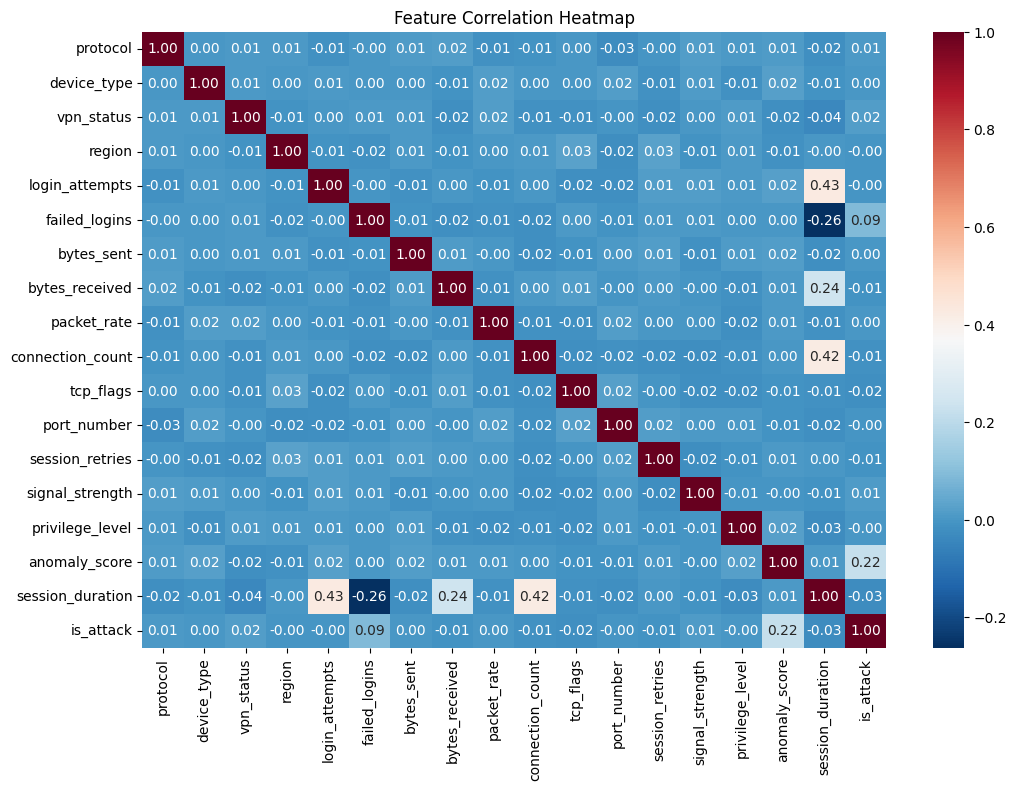

Pre-processing complete. Ready for modeling.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Loading the Dataset
df = pd.read_csv('Dataset1_even_students.csv')

# Handle Missing Values
df['protocol'] = df['protocol'].fillna(df['protocol'].mode()[0])

# Fill numerical missing values with the Median to avoid outlier distortion
df['bytes_received'] = df['bytes_received'].fillna(df['bytes_received'].median())
df['signal_strength'] = df['signal_strength'].fillna(df['signal_strength'].median())

# Categorical Encoding
# Change text columns into numerical values
categorical_cols = ['protocol', 'device_type', 'vpn_status', 'region', 'tcp_flags', 'privilege_level']
le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

# Encode the Classification Target (Benign -> 0, Attack -> 1)
df['is_attack'] = df['is_attack'].map({'Benign': 0, 'Attack': 1})

# Separate features and targets
# Drop the targets and the ID column because it isn't a predictor
X = df.drop(columns=['is_attack', 'session_duration', 'session_id'])
y_clf = df['is_attack']
y_reg = df['session_duration']

# Scale the features
# This makes sure 'bytes_sent' (large) doesn't drown out 'login_attempts' (small)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Feature Selection
# Drop 'session_id' because it has no predictive power
X = df.drop(columns=['session_id', 'session_duration', 'is_attack'])
y_reg = df['session_duration'] # Target for Regression
y_clf = df['is_attack']        # Target for Classification

# Correlation Analysis
plt.figure(figsize=(12, 8))
sns.heatmap(df.drop(columns=['session_id']).corr(), annot=True, cmap='RdBu_r', fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

# Split Data for Modeling
# Regression Split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_scaled, y_clf, test_size=0.2, random_state=42)

# Classification Split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_scaled, y_reg, test_size=0.2, random_state=42)

print("Pre-processing complete. Ready for modeling.")

Training the Classification Model

--- Classification Performance ---
              precision    recall  f1-score   support

           0       0.78      0.98      0.87       933
           1       0.39      0.05      0.09       267

    accuracy                           0.77      1200
   macro avg       0.59      0.51      0.48      1200
weighted avg       0.70      0.77      0.70      1200



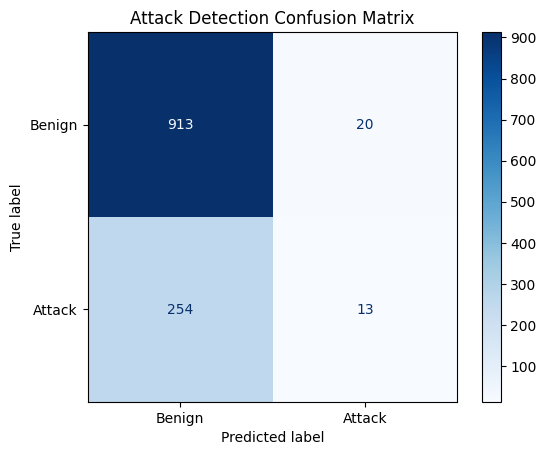

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Initialize and Train the Model
clf_model = RandomForestClassifier(n_estimators=100, random_state=42)
clf_model.fit(X_train_c, y_train_c)

# Make Predictions
y_pred_c = clf_model.predict(X_test_c)

# Print the Evaluation Report
print("--- Classification Performance ---")
print(classification_report(y_test_c, y_pred_c))

# Visualize the Confusion Matrix
# This shows where the model got confused (False Positives vs False Negatives)
cm = confusion_matrix(y_test_c, y_pred_c)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Attack'])
disp.plot(cmap='Blues')
plt.title("Attack Detection Confusion Matrix")
plt.show()

Implementation of Regression Model

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Initialize and Train the Regressor Model
# I used the regression splits (X_train_r, y_train_r) that was made in Step 1
reg_model = RandomForestRegressor(n_estimators=100, random_state=42)
reg_model.fit(X_train_r, y_train_r)

# Make Predictions
y_pred_r = reg_model.predict(X_test_r)

# Evaluate Performance
mae = mean_absolute_error(y_test_r, y_pred_r)
r2 = r2_score(y_test_r, y_pred_r)

print(f"--- Regression Performance ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} seconds")
print(f"R-squared Score: {r2:.4f}")

--- Regression Performance ---
Mean Absolute Error (MAE): 10.20 seconds
R-squared Score: 0.4057
